# Notebook 2: Análisis exploratorio de los 5 activos

**Proyecto:** “¿Qué habría pasado con 100 € al mes?” Una guía con datos para el pequeño inversor en España

**Autores:** Yassine y Adriana

**Objetivo:** analizar los precios limpios del notebook 1 para conocer cada activo (S&P 500, IBEX 35, oro, bitcoin y Nvidia): cómo ha evolucionado su precio, cuánto se mueve, cuántas y qué tan fuertes han sido sus caídas, y qué destaca de cada uno.

**Datos:** `datos/precios_mensuales_eur.csv` (todo en euros, ene-2010 a sep-2026).

## 1. Importar librerías y estilo de los gráficos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Un color fijo para cada activo (siempre el mismo en todos los gráficos)
colores = {
    "sp500":   "#2a78d6",   # azul
    "ibex35":  "#eb6834",   # naranja
    "oro":     "#1baf7a",   # verde agua
    "bitcoin": "#eda100",   # amarillo
    "nvidia":  "#e87ba4",   # rosa
}
nombres = {
    "sp500": "S&P 500", "ibex35": "IBEX 35", "oro": "Oro",
    "bitcoin": "Bitcoin", "nvidia": "Nvidia",
}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#bdbcb5", "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 13,
    "lines.linewidth": 2, "font.size": 10.5,
})
pd.set_option("display.float_format", "{:,.2f}".format)

## 2. Cargar los datos limpios

In [2]:
precios = pd.read_csv("datos/precios_mensuales_eur.csv", index_col="fecha", parse_dates=True)

activos = list(colores.keys())   # los 5 activos (dejamos aparte eur_usd, que es un tipo de cambio)

print("Meses:", len(precios), "| desde", precios.index.min().date(), "hasta", precios.index.max().date())
precios.head()

Meses: 201 | desde 2010-01-01 hasta 2026-09-01


,sp500,ibex35,oro,bitcoin,nvidia,eur_usd
fecha,,,,,,
2010-01-01,773.85,"10,947.69",24.93,NaN,0.25,1.39
2010-02-01,809.87,"10,333.59",26.29,NaN,0.27,1.36
2010-03-01,865.73,"10,871.29",26.50,NaN,0.29,1.35
2010-04-01,892.38,"10,492.19",28.60,NaN,0.27,1.33
2010-05-01,886.57,"9,359.39",31.86,NaN,0.24,1.23


## 3. Primer vistazo: estadísticas básicas

Los precios están en escalas muy distintas (el IBEX vale miles de euros y Nvidia empezó en céntimos), así que miramos el rango: precio inicial, final, mínimo, máximo y cuántas veces se ha multiplicado el precio.

In [3]:
resumen = pd.DataFrame({
    "primer mes":       precios[activos].apply(lambda s: s.first_valid_index().strftime("%Y-%m")),
    "precio inicial €": precios[activos].apply(lambda s: s.dropna().iloc[0]),
    "precio final €":   precios[activos].iloc[-1],
    "mínimo €":         precios[activos].min(),
    "máximo €":         precios[activos].max(),
    "mes del máximo":   precios[activos].idxmax().dt.strftime("%Y-%m"),
})
resumen["precio x veces"] = resumen["precio final €"] / resumen["precio inicial €"]
resumen.rename(index=nombres)

,primer mes,precio inicial €,precio final €,mínimo €,máximo €,mes del máximo,precio x veces
S&P 500,2010-01,773.85,"6,746.90",773.85,"6,746.90",2026-09,8.72
IBEX 35,2010-01,"10,947.69","19,426.20","6,089.79","19,974.10",2026-08,1.77
Oro,2010-01,24.93,117.76,24.93,142.32,2026-02,4.72
Bitcoin,2014-09,306.42,"73,765.43",192.68,"101,349.09",2025-07,240.74
Nvidia,2010-01,0.25,201.38,0.16,201.38,2026-09,794.06


## 4. Evolución del precio de cada activo

Un gráfico por activo, cada uno con su propia escala. El eje vertical es **logarítmico**: la misma distancia significa el mismo % de subida o bajada, así se ven bien las caídas aunque el precio se haya multiplicado mucho.

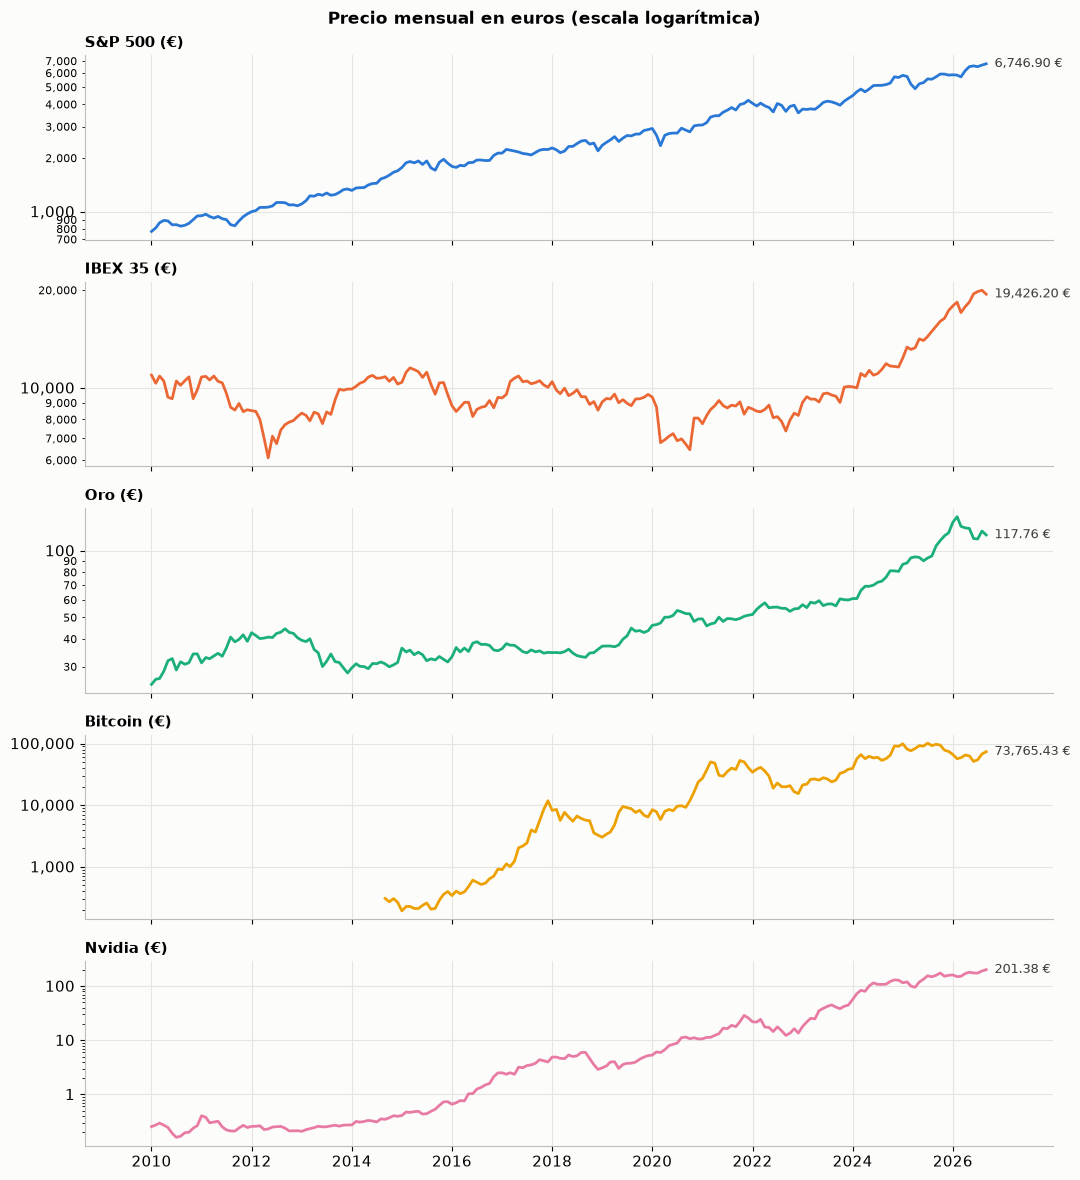

In [4]:
fig, axes = plt.subplots(len(activos), 1, figsize=(11, 12), sharex=True)
for ax, a in zip(axes, activos):
    serie = precios[a].dropna()
    ax.plot(serie.index, serie, color=colores[a])
    ax.set_yscale("log")
    formato = mticker.FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 1 else f"{v:,.2f}")
    ax.yaxis.set_major_formatter(formato)
    # marcas intermedias solo si el precio se mueve en un rango estrecho (si no, se amontonan)
    ax.yaxis.set_minor_formatter(formato if serie.max() / serie.min() < 30 else mticker.NullFormatter())
    ax.tick_params(axis="y", which="minor", labelsize=8)
    ax.set_title(f"{nombres[a]} (€)", loc="left", fontsize=11)
    ax.annotate(f"{serie.iloc[-1]:,.2f} €", (serie.index[-1], serie.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color="#3d3d3a")
fig.suptitle("Precio mensual en euros (escala logarítmica)", fontweight="bold")
axes[-1].margins(x=0.08)
plt.tight_layout()
plt.show()

## 5. Rentabilidad y volatilidad

Pasamos de precios a **rentabilidades mensuales**: cuánto subió o bajó el precio cada mes, en %.

Con ellas calculamos:
- **Crecimiento anual medio del precio:** cuánto ha subido el precio al año, de media.
- **Volatilidad anual:** cuánto se mueve el precio arriba y abajo. Cuanto más alta, más inestable.
- **Mejor y peor mes**, y **% de meses en positivo**.

Lo calculamos desde que existe cada activo y también en el periodo común de los 5 (sep-2014 a sep-2026, porque el bitcoin empieza en 2014), para comparar en igualdad de condiciones.

In [5]:
rent_mensual = precios[activos].pct_change(fill_method=None)   # % de cambio de un mes a otro
inicio_comun = precios["bitcoin"].first_valid_index()          # sep-2014

def metricas(rent):
    rent = rent.dropna()
    años = len(rent) / 12
    return pd.Series({
        "crecimiento anual %": ((1 + rent).prod() ** (1 / años) - 1) * 100,
        "volatilidad anual %": rent.std() * np.sqrt(12) * 100,
        "mejor mes %":         rent.max() * 100,
        "peor mes %":          rent.min() * 100,
        "meses en positivo %": (rent > 0).mean() * 100,
        "años de datos":       años,
    })

tabla_completa = rent_mensual.apply(metricas).T
tabla_comun = rent_mensual.loc[inicio_comun:].apply(metricas).T

print("Desde que existe cada activo (2010, o 2014 en bitcoin):")
display(tabla_completa.rename(index=nombres))
print("Periodo común (sep-2014 a sep-2026):")
display(tabla_comun.rename(index=nombres))

Desde que existe cada activo (2010, o 2014 en bitcoin):


,crecimiento anual %,volatilidad anual %,mejor mes %,peor mes %,meses en positivo %,años de datos
S&P 500,13.87,13.53,14.27,-12.52,65.00,16.67
IBEX 35,3.50,18.80,25.18,-22.21,55.50,16.67
Oro,9.76,15.80,16.10,-13.33,56.50,16.67
Bitcoin,57.93,70.49,64.59,-36.48,55.56,12.00
Nvidia,49.28,43.56,52.22,-28.06,65.00,16.67


Periodo común (sep-2014 a sep-2026):


,crecimiento anual %,volatilidad anual %,mejor mes %,peor mes %,meses en positivo %,años de datos
S&P 500,13.09,14.62,14.27,-12.52,63.45,12.08
IBEX 35,5.04,17.59,25.18,-22.21,56.55,12.08
Oro,11.54,14.04,16.10,-9.95,57.93,12.08
Bitcoin,57.93,70.49,64.59,-36.48,55.56,12.00
Nvidia,69.08,44.36,41.37,-28.06,66.90,12.08


### 5.1 Crecimiento frente a volatilidad

Cada punto es un activo. **Arriba** = su precio ha crecido más, **a la derecha** = su precio se mueve más.

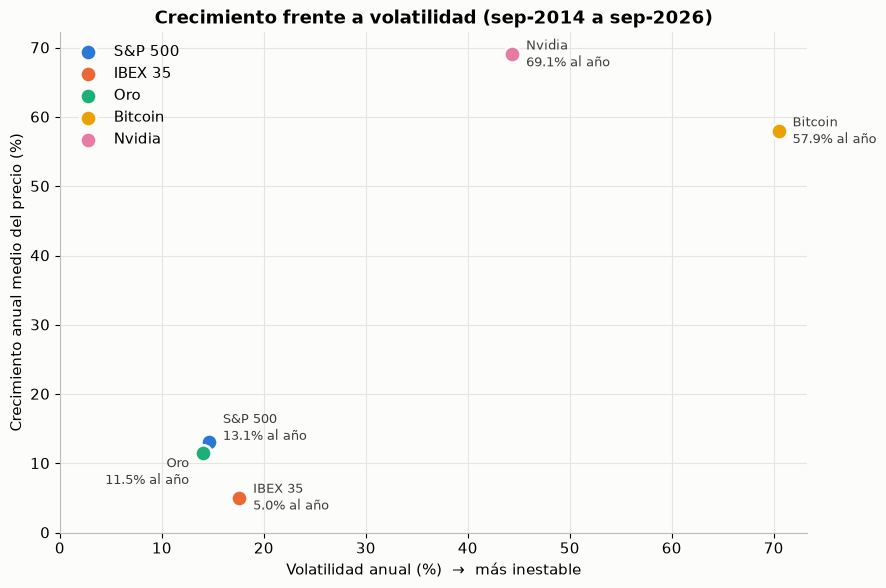

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
for a in activos:
    x = tabla_comun.loc[a, "volatilidad anual %"]
    y = tabla_comun.loc[a, "crecimiento anual %"]
    ax.scatter(x, y, s=140, color=colores[a], edgecolor="#fcfcfb", linewidth=2, zorder=3, label=nombres[a])
    desplaz = {"sp500": (10, 10), "oro": (-10, -14)}.get(a, (10, 0))
    ax.annotate(f"{nombres[a]}\n{y:.1f}% al año", (x, y), xytext=desplaz, textcoords="offset points",
                va="center", ha="right" if desplaz[0] < 0 else "left", fontsize=9.5, color="#3d3d3a")

ax.set_xlabel("Volatilidad anual (%)  →  más inestable")
ax.set_ylabel("Crecimiento anual medio del precio (%)")
ax.set_title("Crecimiento frente a volatilidad (sep-2014 a sep-2026)")
ax.set_xlim(0, None); ax.set_ylim(0, None)
ax.legend(loc="upper left", frameon=False)
ax.margins(x=0.25)
plt.tight_layout()
plt.show()

## 6. Las caídas de cada activo

Miramos las caídas de dos formas:
- **Meses en negativo:** cuántos meses bajó el precio, y cuántos bajó más de un 10 % de golpe.
- **Caída desde el máximo (*drawdown*):** cuánto llegó a estar el precio por debajo de su máximo anterior. Mide lo profunda y lo larga que fue cada mala racha.

> Usamos precios de cierre de mes, así que caídas que duraron solo unos días pueden ser algo mayores en la realidad. El máximo se cuenta desde 2010 (o 2014 en bitcoin), que es donde empiezan nuestros datos.

In [7]:
maximo_hasta_hoy = precios[activos].cummax()             # el máximo alcanzado hasta cada mes
caida = (precios[activos] / maximo_hasta_hoy - 1) * 100  # % por debajo de ese máximo

# ¿Cuántos meses tardó en volver a su máximo tras la peor caída?
def meses_recuperacion(a):
    fondo = caida[a].idxmin()
    despues = caida.loc[fondo:, a]
    recuperado = despues[despues >= 0]
    return (len(caida.loc[fondo:recuperado.index[0], a]) - 1) if len(recuperado) else np.nan

ranking_caidas = pd.DataFrame({
    "caída máxima %":          caida.min(),
    "mes del fondo":           caida.idxmin().dt.strftime("%Y-%m"),
    "meses en recuperarse":    [meses_recuperacion(a) for a in activos],
    "meses en negativo":       (rent_mensual < 0).sum(),
    "% meses en negativo":     (rent_mensual < 0).sum() / rent_mensual.notna().sum() * 100,
    "meses con caída > 10 %":  (rent_mensual < -0.10).sum(),
    "peor mes":                rent_mensual.idxmin().dt.strftime("%Y-%m"),
    "% del tiempo > 20 % bajo su máximo": (caida < -20).sum() / precios[activos].notna().sum() * 100,
    "caída actual %":          caida.iloc[-1],
})
ranking_caidas.sort_values("caída máxima %").rename(index=nombres)

,caída máxima %,mes del fondo,meses en recuperarse,meses en negativo,% meses en negativo,meses con caída > 10 %,peor mes,% del tiempo > 20 % bajo su máximo,caída actual %
Bitcoin,-74.39,2019-01,21,64,44.44,29,2021-05,55.86,-27.22
Nvidia,-57.28,2022-09,8,70,35.00,23,2022-04,35.82,0.00
IBEX 35,-44.37,2012-05,33,89,44.50,5,2020-03,40.30,-2.74
Oro,-36.79,2013-12,68,87,43.50,3,2013-06,25.87,-17.26
S&P 500,-19.88,2020-03,5,70,35.00,1,2020-03,0.00,0.00


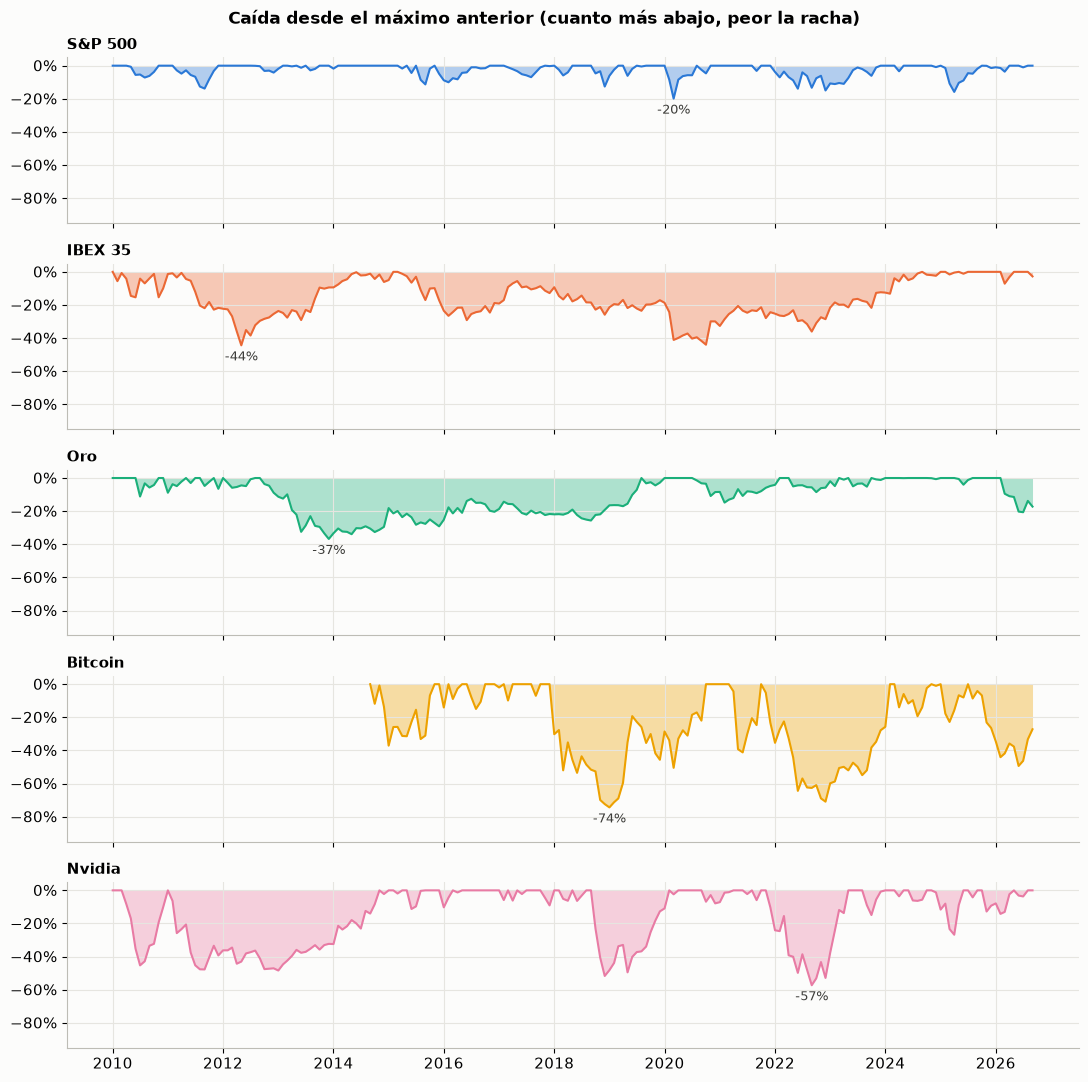

In [8]:
fig, axes = plt.subplots(len(activos), 1, figsize=(11, 11), sharex=True, sharey=True)
for ax, a in zip(axes, activos):
    ax.fill_between(caida.index, caida[a], 0, color=colores[a], alpha=0.35, linewidth=0)
    ax.plot(caida.index, caida[a], color=colores[a], linewidth=1.5)
    fondo = caida[a].idxmin()
    ax.annotate(f"{caida[a].min():.0f}%", (fondo, caida[a].min()), xytext=(0, -4),
                textcoords="offset points", ha="center", va="top", fontsize=9, color="#3d3d3a")
    ax.set_ylim(-95, 5)
    ax.set_title(nombres[a], loc="left", fontsize=11)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
fig.suptitle("Caída desde el máximo anterior (cuanto más abajo, peor la racha)", fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Variación del precio año a año

Cada casilla es cuánto subió (azul) o bajó (rojo) el precio en un año natural.

> Años incompletos: 2010 empieza en febrero (hace falta el mes anterior para calcular la variación), el bitcoin en 2014 solo tiene oct-dic y 2026 llega hasta septiembre.

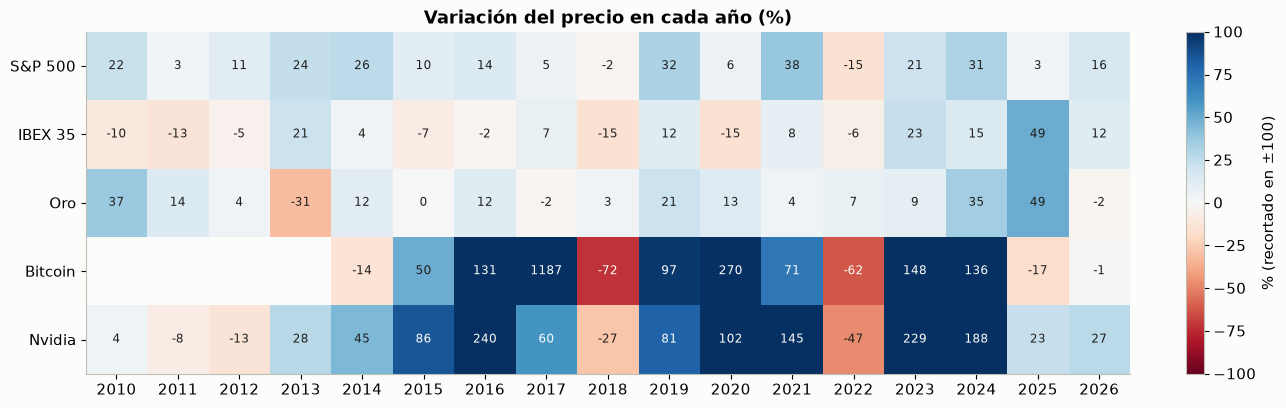

,S&P 500,IBEX 35,Oro,Bitcoin,Nvidia
año,,,,,
2010,22.18,-9.94,37.26,NaN,4.40
2011,2.66,-13.11,13.94,NaN,-7.60
2012,11.08,-4.66,3.80,NaN,-12.80
2013,24.14,21.42,-30.64,NaN,27.89
2014,26.48,3.66,11.54,-13.61,44.66
2015,10.42,-7.15,0.45,49.83,85.89
2016,13.85,-2.01,12.40,131.13,239.83
2017,4.69,7.40,-1.67,"1,186.66",59.54
2018,-1.65,-14.97,3.20,-72.39,-27.43


In [9]:
rent_anual = (1 + rent_mensual).groupby(rent_mensual.index.year).prod() - 1
rent_anual = rent_anual.where(rent_mensual.notna().groupby(rent_mensual.index.year).any()) * 100
rent_anual.index.name = "año"

valores = rent_anual[activos].T
limite = 100                                         # recortamos la escala de color en ±100%
fig, ax = plt.subplots(figsize=(13, 4.2))
im = ax.imshow(valores.clip(-limite, limite), cmap="RdBu", vmin=-limite, vmax=limite, aspect="auto")
for i, a in enumerate(activos):
    for j, año in enumerate(valores.columns):
        v = valores.loc[a, año]
        if pd.notna(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
                    color="#fcfcfb" if abs(v) > 55 else "#1f1f1d")
ax.set_xticks(range(len(valores.columns)), valores.columns)
ax.set_yticks(range(len(activos)), [nombres[a] for a in activos])
ax.grid(False)
ax.set_title("Variación del precio en cada año (%)")
fig.colorbar(im, ax=ax, label="% (recortado en ±100)", fraction=0.025)
plt.tight_layout()
plt.show()

rent_anual[activos].rename(columns=nombres)

In [10]:
pd.DataFrame({
    "años en negativo": (rent_anual[activos] < 0).sum(),
    "años con datos":   rent_anual[activos].notna().sum(),
    "mejor año":        rent_anual[activos].idxmax(),
    "peor año":         rent_anual[activos].idxmin(),
}).rename(index=nombres)

,años en negativo,años con datos,mejor año,peor año
S&P 500,2,17,2021,2022
IBEX 35,8,17,2025,2020
Oro,3,17,2025,2013
Bitcoin,5,13,2017,2018
Nvidia,4,17,2016,2022


## 8. ¿Se mueven juntos? Correlaciones

La **correlación** va de -1 a 1:
- **cerca de 1:** los dos activos suben y bajan a la vez,
- **cerca de 0:** cada uno va por su cuenta,
- **negativa:** cuando uno sube, el otro tiende a bajar.

Usamos las rentabilidades mensuales del periodo común (sep-2014 a sep-2026).

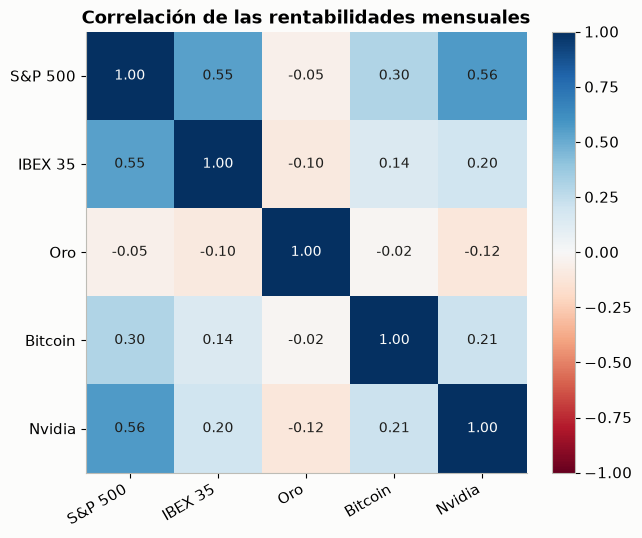

,S&P 500,IBEX 35,Oro,Bitcoin,Nvidia
S&P 500,1.00,0.55,-0.05,0.30,0.56
IBEX 35,0.55,1.00,-0.10,0.14,0.20
Oro,-0.05,-0.10,1.00,-0.02,-0.12
Bitcoin,0.30,0.14,-0.02,1.00,0.21
Nvidia,0.56,0.20,-0.12,0.21,1.00


In [11]:
corr = rent_mensual.loc[inicio_comun:, activos].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
for i in range(len(activos)):
    for j in range(len(activos)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=10,
                color="#fcfcfb" if abs(corr.iloc[i, j]) > 0.6 else "#1f1f1d")
etiquetas = [nombres[a] for a in activos]
ax.set_xticks(range(len(activos)), etiquetas, rotation=30, ha="right")
ax.set_yticks(range(len(activos)), etiquetas)
ax.grid(False)
ax.set_title("Correlación de las rentabilidades mensuales")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

corr.rename(index=nombres, columns=nombres)

## 9. El efecto del euro-dólar

El S&P 500 y Nvidia cotizan en dólares y en el notebook 1 los pasamos a euros. Por eso su precio en euros depende también del tipo de cambio: si el euro **baja** frente al dólar, esos activos valen **más** en euros (y al revés).

Comparamos el S&P 500 medido en dólares y en euros.

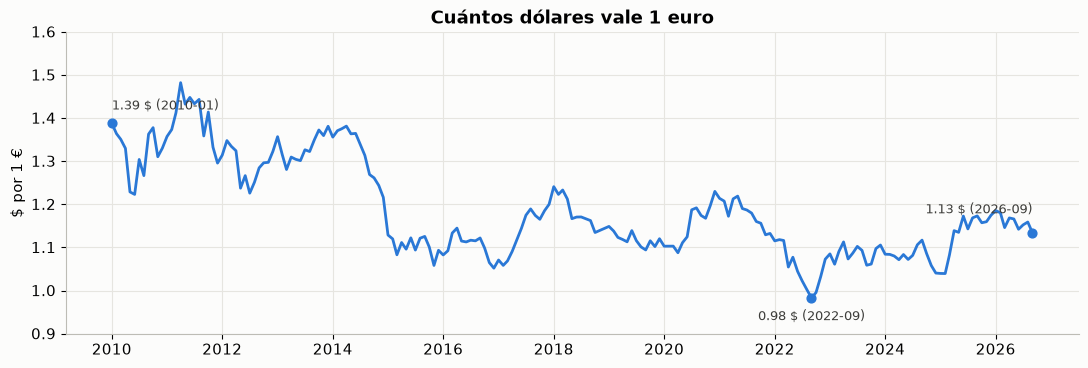

,crecimiento anual % (2010-2026)
S&P 500 en dólares,12.50
S&P 500 en euros,13.87


In [12]:
sp500_usd = precios["sp500"] * precios["eur_usd"]     # deshacemos la conversión del notebook 1
años = (len(precios) - 1) / 12

comparacion = pd.Series({
    "S&P 500 en dólares": ((sp500_usd.iloc[-1] / sp500_usd.iloc[0]) ** (1 / años) - 1) * 100,
    "S&P 500 en euros":   ((precios["sp500"].iloc[-1] / precios["sp500"].iloc[0]) ** (1 / años) - 1) * 100,
}).to_frame("crecimiento anual % (2010-2026)")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(precios.index, precios["eur_usd"], color="#2a78d6")
ax.set_title("Cuántos dólares vale 1 euro")
ax.set_ylabel("$ por 1 €")
for fecha, alin, dy in [(precios.index[0], "left", 10), (precios["eur_usd"].idxmin(), "center", -16),
                        (precios.index[-1], "right", 14)]:
    v = precios.loc[fecha, "eur_usd"]
    ax.scatter(fecha, v, s=40, color="#2a78d6", zorder=3)
    ax.annotate(f"{v:.2f} $ ({fecha:%Y-%m})", (fecha, v), xytext=(0, dy), textcoords="offset points",
                ha=alin, fontsize=9, color="#3d3d3a")
ax.set_ylim(0.9, 1.6)
plt.tight_layout()
plt.show()

comparacion